# Phase 2, M2: views and QA for every KOI (10/24/2026)

`sweeps/p2_build.jl` detrended all 7,927 cached stars and built the views (global, local, odd, even, secondary,
centroid) plus QA columns for every KOI on them: 9,271 KOIs, 0 errors, 1.4 h. This notebook checks the result.

**M2 gate (PHASE2_PLAN.md):** the EB average shows a secondary, the planet average is U-shaped, and there are no
systematic artifacts. Coverage and QA flags are computed for every KOI **without labels**. Everything that uses labels
(class averages) is computed on the **pool only**; test-split KOIs are counted but never looked at by class.

In [1]:
include(joinpath(@__DIR__, "..", "src", "VettingSetup.jl"))
df_raw = load_koi()
df = clean_koi(df_raw)
pool, test = cv_pool(df)
V = JLD2.load(joinpath(DATA_DIR, "views_all.jld2"))
qa = CSV.read(joinpath(CV_DIR, "p2_qa.csv"), DataFrame)
col = Dict(n => i for (i, n) in enumerate(V["names"]))
@printf("views for %d KOIs | cleaned KOIs with views: %d / %d (pool %d / %d, test %d / %d)\n", length(V["names"]),
        count(n -> haskey(col, n), df.kepoi_name), nrow(df), count(n -> haskey(col, n), pool.kepoi_name), nrow(pool),
        count(n -> haskey(col, n), test.kepoi_name), nrow(test))

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
views for 9271 KOIs | cleaned KOIs with views: 9201 / 9201 (pool 8288 / 8288, test 913 / 913)


## 1. QA columns (all KOIs, no labels)
- **Observed transits:** transits with data inside ±0.5 duration.
- **Depth ratio:** our local-view depth / the catalog `koi_depth`. Near 1 means our fold and detrending reproduce
  the catalog signal; far off points to a wrong ephemeris, dilution by other KOIs on the star, or detrending damage.
- **Timing scatter:** robust scatter of the per-transit centre offsets, in durations. It is only meaningful when
  single transits are clearly detected, so it is plotted against the per-transit SNR
  (catalog depth / σ × √(cadences per transit); the catalog depth, because our own depth is noise-dominated for
  the weakest signals).

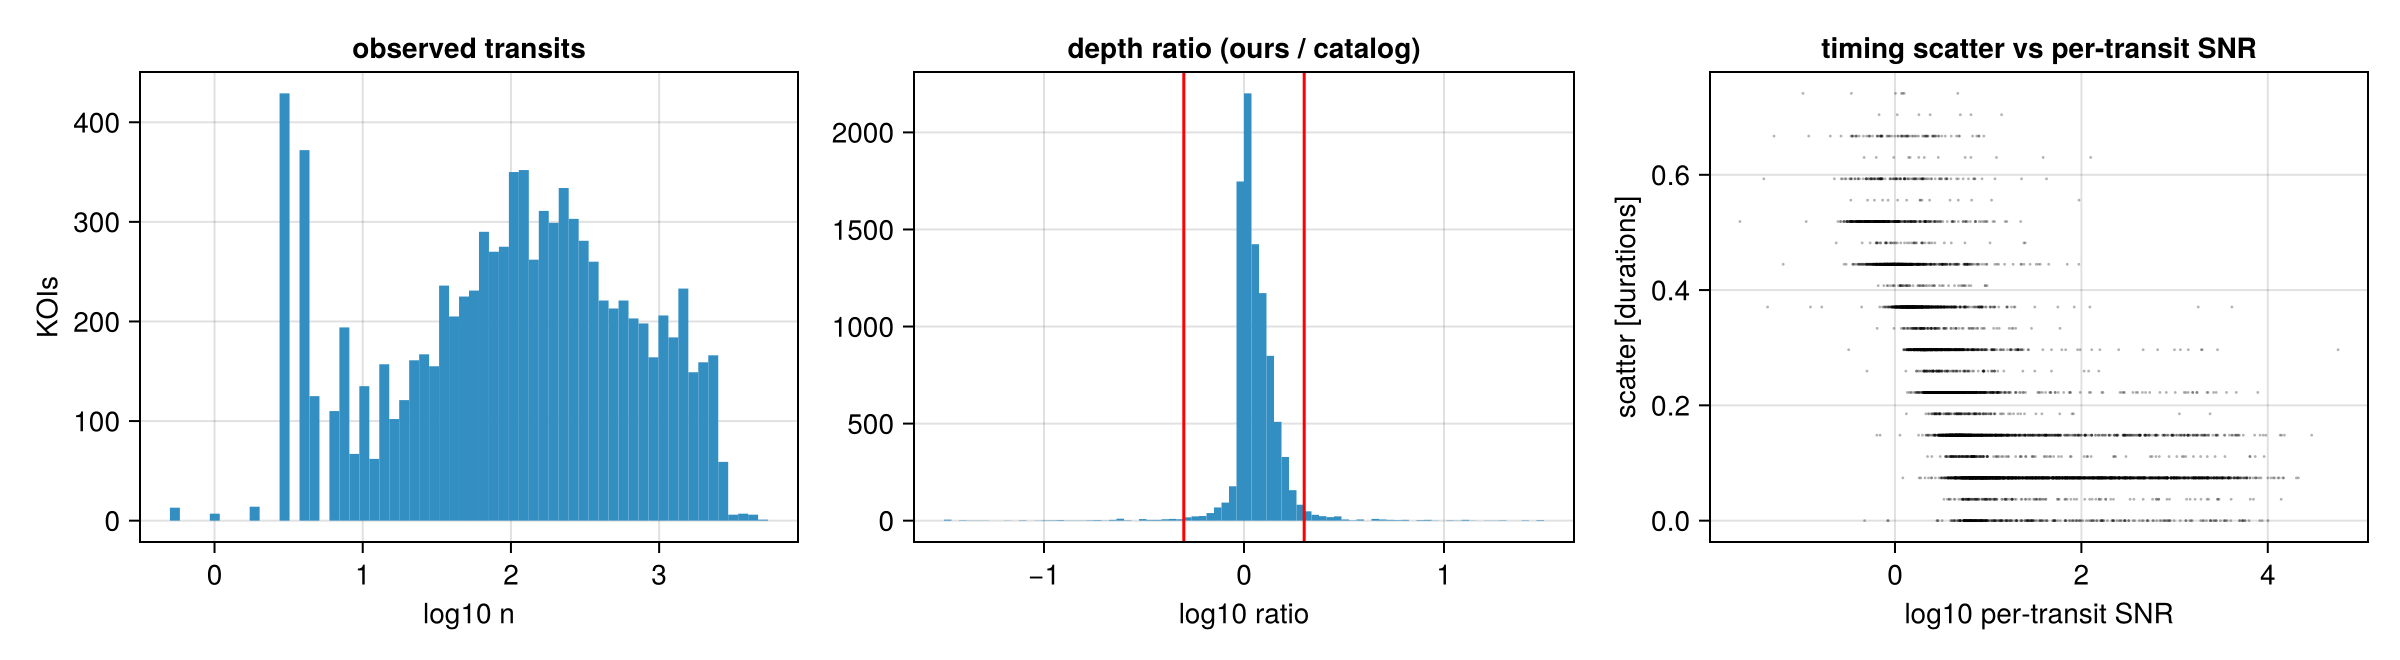

In [2]:
qa = leftjoin(qa, df_raw[:, [:kepoi_name, :koi_duration, :koi_period]]; on = :kepoi_name, order = :left)
for c in names(qa)            # missing catalog values (e.g. no koi_depth) -> NaN, so they drop out of plots and flags
    nonmissingtype(eltype(qa[!, c])) <: AbstractFloat && (qa[!, c] = Float64.(coalesce.(qa[!, c], NaN)))
end
qa.snr1 = 1e-6 .* qa.koi_depth ./ qa.sigma .* sqrt.(qa.koi_duration ./ 24 ./ 0.02043)   # catalog depth: robust to noise
fig = Figure(size = (1200, 330))
ax1 = Axis(fig[1, 1]; title = "observed transits", xlabel = "log10 n", ylabel = "KOIs")
hist!(ax1, log10.(max.(qa.n_transits, 0.5)); bins = 60)
ax2 = Axis(fig[1, 2]; title = "depth ratio (ours / catalog)", xlabel = "log10 ratio")
r = filter(isfinite, log10.(qa.depth_ratio))
hist!(ax2, clamp.(r, -1.5, 1.5); bins = 80); vlines!(ax2, [log10(0.5), log10(2)]; color = :red)
ax3 = Axis(fig[1, 3]; title = "timing scatter vs per-transit SNR", xlabel = "log10 per-transit SNR",
           ylabel = "scatter [durations]")
ok = isfinite.(qa.timing_scatter) .& isfinite.(qa.snr1) .& (qa.snr1 .> 0)
scatter!(ax3, log10.(qa.snr1[ok]), qa.timing_scatter[ok]; markersize = 2, color = (:black, 0.3))
fig

Below a per-transit SNR of a few, single transits are not detected and the "offset" is noise, so the scatter as
first built (flag > 0.25 durations, 3,095 KOIs) mostly flags noise. The refined flag only counts KOIs whose single
transits are clearly detected (per-transit SNR ≥ 7).

In [3]:
qa.qa_timing = coalesce.((qa.snr1 .>= 7) .& (qa.timing_scatter .> 0.25), false)
summ = DataFrame(flag = ["< 2 observed transits", "local view > 50% empty", "depth ratio < 0.5 or > 2",
                         "timing scatter > 0.25 dur (per-transit SNR ≥ 7)"],
                 kois = [sum(qa.qa_few_transits), sum(qa.qa_empty), sum(qa.qa_depth_mismatch), sum(qa.qa_timing)])
summ.percent = round.(100 .* summ.kois ./ nrow(qa); digits = 2)
summ

Row,flag,kois,percent
,String,Int64,Float64
1,< 2 observed transits,20,0.22
2,local view > 50% empty,3,0.03
3,depth ratio < 0.5 or > 2,291,3.14
4,timing scatter > 0.25 dur (per-transit SNR ≥ 7),222,2.39


Some of the most extreme timing-scatter KOIs at high SNR (expect known TTV systems such as Kepler-9 = K00377):

In [4]:
first(sort(qa[qa.qa_timing, [:kepoi_name, :koi_period, :n_transits, :snr1, :timing_scatter, :depth_ratio]],
           :timing_scatter; rev = true), 10)

Row,kepoi_name,koi_period,n_transits,snr1,timing_scatter,depth_ratio
,DataStri…,Float64,Int64,Float64,Float64,Float64
1,K06181.01,24.0734,56,13.9316,0.704235,3.01514
2,K08099.01,333.716,3,8.97771,0.66717,1.99277
3,K07568.01,480.038,3,7.98785,0.66717,0.835113
4,K05337.01,470.654,3,7.5483,0.66717,0.791773
5,K05624.01,502.658,3,7.93534,0.66717,0.898969
6,K03936.01,141.609,10,12.2671,0.630105,1.6782
7,K01770.01,63.9355,22,38.889,0.630105,1.31181
8,K00134.01,67.5924,22,125.794,0.630105,0.30749
9,K03965.01,12.4256,113,8.58846,0.59304,1.44511


## 2. Average views per class (pool only)
Median view per class, so a few odd KOIs cannot dominate. Planets = CONFIRMED + CANDIDATE; FP classes by robovetter
flag, each "pure" (that flag only), as in M0. Labels and flags are used only to group KOIs here, never as inputs.

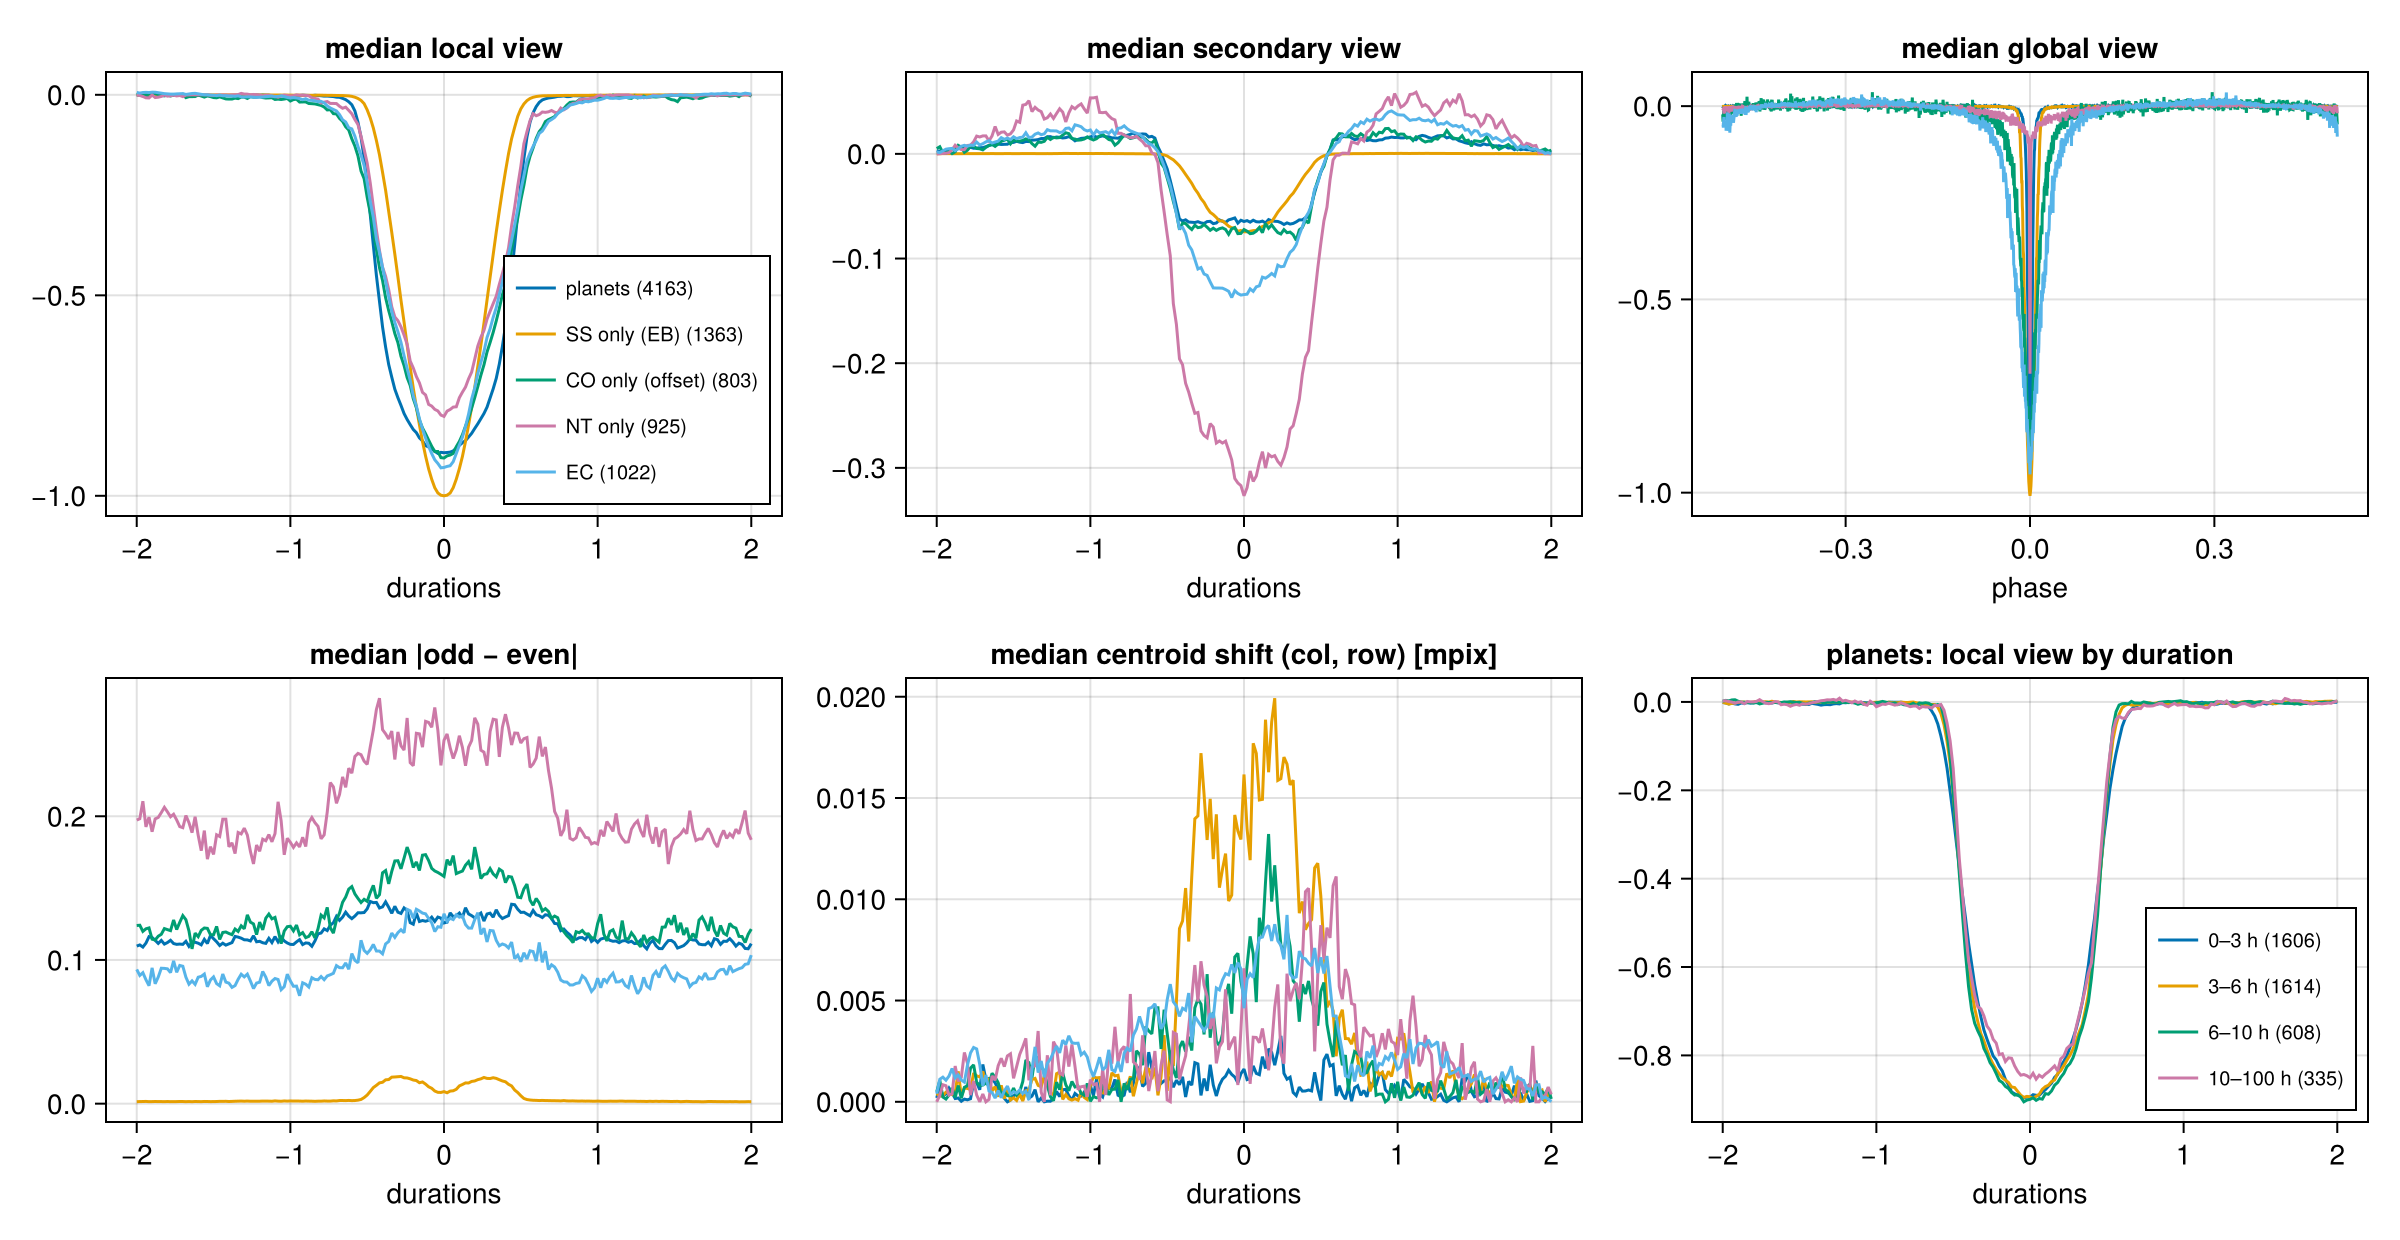

In [5]:
info = leftjoin(pool[:, [:kepoi_name, :label, :koi_duration]],
                df_raw[:, [:kepoi_name, :koi_fpflag_nt, :koi_fpflag_ss, :koi_fpflag_co, :koi_fpflag_ec]];
                on = :kepoi_name, order = :left)
info.dr25 = is_dr25(info, df_raw)
filter!(r -> haskey(col, r.kepoi_name), info)
fl(r, f) = coalesce(r[f], 0) == 1
classes = [("planets", r -> r.label == 1),
           ("SS only (EB)", r -> r.label == 0 && fl(r, :koi_fpflag_ss) && !fl(r, :koi_fpflag_co) && !fl(r, :koi_fpflag_nt)),
           ("CO only (offset)", r -> r.label == 0 && fl(r, :koi_fpflag_co) && !fl(r, :koi_fpflag_ss) && !fl(r, :koi_fpflag_nt)),
           ("NT only", r -> r.label == 0 && fl(r, :koi_fpflag_nt) && !fl(r, :koi_fpflag_ss) && !fl(r, :koi_fpflag_co)),
           ("EC", r -> r.label == 0 && fl(r, :koi_fpflag_ec))]
members = [(c, [r.kepoi_name for r in eachrow(info) if f(r)]) for (c, f) in classes]
medview(key, names) = vec(median(V[key][:, [col[n] for n in names]]; dims = 2))
xl = range(-LOCAL_SPAN, LOCAL_SPAN; length = N_LOCAL); xg = range(-0.5, 0.5; length = N_GLOBAL)
fig = Figure(size = (1200, 620))
panels = [("local_view", "local", xl), ("secondary", "secondary", xl), ("global_view", "global", xg)]
for (j, (key, ttl, x)) in enumerate(panels)
    ax = Axis(fig[1, j]; title = "median $ttl view", xlabel = j == 3 ? "phase" : "durations")
    for (c, ns) in members
        lines!(ax, x, medview(key, ns); label = "$c ($(length(ns)))")
    end
    j == 1 && axislegend(ax; position = :rb, labelsize = 10)
end
ax = Axis(fig[2, 1]; title = "median |odd − even|", xlabel = "durations")
for (c, ns) in members
    lines!(ax, xl, vec(median(abs.(V["odd"][:, [col[n] for n in ns]] .- V["even"][:, [col[n] for n in ns]]); dims = 2)))
end
ax = Axis(fig[2, 2]; title = "median centroid shift (col, row) [mpix]", xlabel = "durations")
for (c, ns) in members
    lines!(ax, xl, 1e3 .* hypot.(medview("cen1", ns), medview("cen2", ns)))
end
ax = Axis(fig[2, 3]; title = "planets: local view by duration", xlabel = "durations")
pl = info[info.label .== 1, :]
for (lo, hi) in [(0, 3), (3, 6), (6, 10), (10, 100)]
    ns = pl.kepoi_name[lo .<= pl.koi_duration .< hi]
    lines!(ax, xl, medview("local_view", ns); label = "$(lo)–$(hi) h ($(length(ns)))")
end
axislegend(ax; position = :rb, labelsize = 10)
fig

## 3. Simple per-class numbers (pool)
The fraction of each class whose secondary view dips below −0.1 (10% of the primary depth) at its centre, the median
in-transit centroid shift, and the median depth ratio. These preview the Phase 2a features of M3.

In [6]:
mid = 95:107
sec_min(n) = minimum(V["secondary"][mid, col[n]])
cshift(n) = 1e3 * hypot(mean(V["cen1"][mid, col[n]]), mean(V["cen2"][mid, col[n]]))
qd = Dict(r.kepoi_name => r.depth_ratio for r in eachrow(qa))
DataFrame(class = first.(members), kois = length.(last.(members)),
          secondary_below_0p1 = [round(mean(sec_min.(ns) .< -0.1); digits = 2) for (_, ns) in members],
          median_centroid_mpix = [round(median(cshift.(ns)); digits = 2) for (_, ns) in members],
          median_depth_ratio = [round(median(filter(isfinite, [qd[n] for n in ns])); digits = 2) for (_, ns) in members])

Row,class,kois,secondary_below_0p1,median_centroid_mpix,median_depth_ratio
,String,Int64,Float64,Float64,Float64
1,planets,4163,0.7,0.06,1.12
2,SS only (EB),1363,0.5,1.48,0.99
3,CO only (offset),803,0.73,0.47,1.21
4,NT only,925,0.95,0.12,1.28
5,EC,1022,0.81,0.22,1.18


Is Kepler-9 b (K00377.01, strong known TTVs, the smeared fold in M0) caught by the refined timing flag?

In [7]:
qa[qa.kepoi_name .== "K00377.01", [:kepoi_name, :n_transits, :snr1, :timing_scatter, :qa_timing]]

Row,kepoi_name,n_transits,snr1,timing_scatter,qa_timing
,DataStri…,Int64,Float64,Float64,Bool
1,K00377.01,70,93.9267,0.44478,true


## 4. M2 findings and gate

**Coverage:** every one of the 9,201 cleaned KOIs (pool 8,288, test 913) has views; 9,271 KOIs in total, including
KOIs outside the cleaned set. 0 errors after one fix: K06549.01 has a catalog duration longer than its period, so
masking its transits left nothing to detrend with. Masks are now capped at P/4 only when they would cover > 80% of
a star's points, so no other star changed.

**QA flags (label-free; `sweeps/results/p2_qa.csv`):** 20 KOIs with < 2 observed transits, 3 with mostly empty
local views, 291 (3.1%) with our depth > 2× off the catalog, and 222 (2.4%) with large timing scatter where single
transits are clearly detected. The first timing flag (3,095 KOIs) counted noise at low SNR. The depth ratio peaks
at ~1.1: binned minima are biased slightly deep, but there is no systematic failure.

**Gate: passed, with one honest qualification.**
- Planets are **U-shaped** with flat bottoms. Pure SS (EB) FPs are **V-shaped**, narrower and reach the full
  depth. Long-duration planets (> 10 h) fold almost identically (−0.85 vs −0.9 at the bottom), so the 3×-duration
  biweight window does not visibly eat long transits.
- **No systematic artifacts** in the median global views (flat out of transit for every class).
- **The secondary and odd/even signals exist but are mostly drowned by noise in per-class medians.** The EB median
  secondary is a smooth real dip, whereas the other classes show the flat "deepest-noise" box at about −0.07. NT
  FPs have the deepest "secondaries", because their light curves are dominated by variability. In median
  |odd − even| the noise level sets the curve: the EBs are the lowest because their signals are the strongest.
  So the Phase 2a features (M3) must be **significances** (depth / its uncertainty), not raw view values, exactly
  as planned. The class-level table above previews this: centroid shift separates SS/CO from planets, while raw
  secondary minima do not.

**Next: M3 (Phase 2a).** About 10 light-curve features computed from the cache with uncertainties (odd/even σ,
secondary σ, V-shape from a trapezoid fit, single-event dominance, timing scatter, coverage), plus centroid
significance for the "+ centroid" family only. Then the Phase 1 tree/MLP CV protocol, paired against Phase 1.